# Classification Experiments, Version 4
Yang Xiao (yx752)

## Step 0: Data and Fixed Split
Compare the v3 approach with additional format-independent features and more varied formatting augmentation. Settings and blend weights use training-only out-of-fold predictions; the shared development partition is used afterward. The development set has already informed previous iterations, so it is not an untouched final test. Dependencies: numpy, pandas, scipy, scikit-learn and matplotlib. Run cells in order to produce the CSV.

In [1]:
from pathlib import Path
from collections import Counter
import re, json, time, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

SEED=27
paths=[Path('data'),Path('.'),Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')]
DATA=next((p for p in paths if (p/'train.csv').exists()),None)
if DATA is None:raise FileNotFoundError('Place competition CSVs in data/ beside this notebook.')
OUT=Path('v4_results');OUT.mkdir(exist_ok=True)
train=pd.read_csv(DATA/'train.csv');test=pd.read_csv(DATA/'test.csv')
sample=pd.read_csv(DATA/'sample_submission.csv')
tr,va=train_test_split(np.arange(len(train)),test_size=2000,stratify=train.label,random_state=SEED)
y=train.label.to_numpy()[tr];yv=train.label.to_numpy()[va]
assert len(tr)==8000 and len(va)==2000 and train.id.is_unique
train.iloc[va][['id']].to_csv(OUT/'val_ids.csv',index=False)
print('Training:',len(tr),'Development:',len(va),'Seed:',SEED)

Training: 8000 Development: 2000 Seed: 27


## Step 1: Features and Formatting Views
Retain the 73 v3 features. Additional features describe character n-gram entropy, normalized compression length, word/trigram diversity, local token diversity, suffix frequencies and adjacent-sentence lexical overlap. They are computed from a canonical text copy, making the added features insensitive to the tested whitespace and typography changes. Raw structural features remain available. All extraction is per passage without labels or fitted corpus statistics.

In [2]:
def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

def expanded_features(text):
    features=extract_style_features(text)
    words=re.findall(r"[a-z]+(?:['’][a-z]+)?",text.lower())
    n=max(len(words),1);nc=max(len(text),1)
    counts=Counter(words)
    values=np.asarray(list(counts.values()),dtype=float)
    lengths=np.asarray([len(w) for w in words],dtype=float)
    sentence_text=[s for s in re.split(r'[.!?]+(?:["\'”’)]*)\s+|\n+',text) if s.strip()]
    sentence_lengths=np.asarray([len(re.findall(r'\b\w+\b',s)) for s in sentence_text],dtype=float)
    for name,array in [('token_length',lengths),('sentence_length',sentence_lengths)]:
        for q in [10,25,50,75,90]:features[f'{name}_q{q}']=float(np.percentile(array,q)) if len(array) else 0.
    features['hapax_ratio']=float(np.sum(values==1)/max(len(values),1))
    features['dislegomena_ratio']=float(np.sum(values==2)/max(len(values),1))
    features['token_entropy']=float(-np.sum((values/n)*np.log(values/n))) if len(values) else 0.
    features['top_token_fraction']=float(values.max()/n) if len(values) else 0.
    features['long_word_fraction']=float(np.mean(lengths>=8)) if len(lengths) else 0.
    features['short_word_fraction']=float(np.mean(lengths<=3)) if len(lengths) else 0.
    groups={
        'first_person':'i me my mine we us our ours',
        'second_person':'you your yours yourself yourselves',
        'third_person':'he him his she her hers they them their theirs',
        'articles':'a an the',
        'prepositions':'of in on at for from to with by about into over under between through',
        'conjunctions':'and or but so because although while whereas if unless since',
        'modals':'can could may might must shall should will would',
        'negations':"no not never neither nor cannot don't doesn't didn't isn't aren't wasn't weren't",
        'demonstratives':'this that these those',
        'be_forms':'am is are was were be been being',
        'have_forms':'have has had having',
    }
    for name,group in groups.items():features[name+'_fraction']=sum(counts[w] for w in group.split())/n
    for char,name in [('"','straight_quote'),("'",'apostrophe'),('(','open_parenthesis'),(')','close_parenthesis'),('[','bracket'),('/','slash'),('-','hyphen'),('%','percent'),(chr(10),'newline')]:
        features[name+'_per_100_words']=100*text.count(char)/n
    features['non_ascii_fraction']=sum(ord(c)>127 for c in text)/nc
    features['whitespace_fraction']=sum(c.isspace() for c in text)/nc
    features['double_space_fraction']=len(re.findall(r' {2,}',text))/nc
    features['sentence_short_fraction']=float(np.mean(sentence_lengths<8)) if len(sentence_lengths) else 0.
    features['sentence_long_fraction']=float(np.mean(sentence_lengths>30)) if len(sentence_lengths) else 0.
    features['list_line_fraction']=len(re.findall(r'(?m)^\s*(?:[-*•]|\d+[.)])\s+',text))/max(len(text.splitlines()),1)
    return features

def canonicalize(text):
    return re.sub(r'\s+',' ',str(text)).translate(str.maketrans({'’':"'",'‘':"'",'“':'"','”':'"','—':'-','–':'-','…':'...'})).strip()

In [3]:
def reflow(text):
    text=canonicalize(text)
    sentences=re.split(r'(?<=[.!?])\s+',text)
    return '\n\n'.join(' '.join(sentences[i:i+2]) for i in range(0,len(sentences),2))

def rich_features(text):
    f=expanded_features(text)
    normalized=canonicalize(text).lower()
    words=re.findall(r"[a-z]+(?:'[a-z]+)?",normalized)
    n=max(len(words),1)
    compact=re.sub(r'\s+',' ',normalized)
    encoded=compact.encode('utf-8')
    f['compression_ratio']=len(zlib.compress(encoded))/max(len(encoded),1)
    for width in [1,2,3]:
        grams=[compact[i:i+width] for i in range(max(0,len(compact)-width+1))]
        counts=np.asarray(list(Counter(grams).values()),float)
        probs=counts/max(counts.sum(),1)
        f[f'char_{width}_entropy']=float(-np.sum(probs*np.log(probs)))
        f[f'char_{width}_unique_ratio']=len(counts)/max(len(grams),1)
    for width in [2,3,4]:
        grams=[tuple(words[i:i+width]) for i in range(max(0,len(words)-width+1))]
        counts=np.asarray(list(Counter(grams).values()),float)
        probs=counts/max(counts.sum(),1)
        f[f'word_{width}_entropy']=float(-np.sum(probs*np.log(probs)))
        f[f'word_{width}_repeat']=float(np.maximum(counts-1,0).sum()/max(len(grams),1))
    windows=[words[i:i+30] for i in range(0,max(len(words)-29,1),15)]
    diversities=[len(set(w))/max(len(w),1) for w in windows]
    f['local_diversity_mean']=float(np.mean(diversities)) if diversities else 0.
    f['local_diversity_std']=float(np.std(diversities)) if diversities else 0.
    for suffix in ['ing','ed','ly','tion','ment','ness','able','ous']:
        f['suffix_'+suffix]=sum(w.endswith(suffix) for w in words)/n
    sentence_text=[s for s in re.split(r'(?<=[.!?])\s+',normalized) if s.strip()]
    sentence_words=[re.findall(r'[a-z]+',s) for s in sentence_text]
    sets=[set(w) for w in sentence_words]
    overlap=[len(a&b)/max(len(a|b),1) for a,b in zip(sets,sets[1:])]
    f['adjacent_jaccard_mean']=float(np.mean(overlap)) if overlap else 0.
    f['adjacent_jaccard_std']=float(np.std(overlap)) if overlap else 0.
    f['adjacent_jaccard_max']=float(np.max(overlap)) if overlap else 0.
    starts=[w[0] for w in sentence_words if w]
    f['sentence_start_repeat']=(len(starts)-len(set(starts)))/max(len(starts),1)
    f['sentence_lexical_diversity']=float(np.mean([len(set(w))/max(len(w),1) for w in sentence_words])) if sentence_words else 0.
    f['long_word_10_fraction']=sum(len(w)>=10 for w in words)/n
    f['punctuation_run_per_word']=len(re.findall(r'[!?.,;:]{2,}',normalized))/n
    f['quoted_span_per_word']=len(re.findall(r'"[^"\n]+"',normalized))/n
    return f

start=time.perf_counter()
views=[train.text.astype(str),train.text.map(canonicalize),train.text.map(reflow)]
frames=[pd.DataFrame([rich_features(t) for t in view]) for view in views]
names=list(frames[0].columns);base_names=list(expanded_features('').keys())
assert len(base_names)==73
matrices=[frame.to_numpy() for frame in frames]
assert all(np.isfinite(z).all() for z in matrices)
base_columns=[names.index(k) for k in base_names]
print('v3 features:',len(base_names),'v4 features:',len(names),'Extraction seconds:',round(time.perf_counter()-start,1))

v3 features: 73 v4 features: 104 Extraction seconds: 106.9


## Step 2: Training-Only Model Search
The baseline retains v3’s 25% flat-format augmentation. New candidates compare 25%, 50% and 75% total augmentation, split equally between flattened and reflowed text. HGB compares 15/31 leaves and L2 values 1/10; RBF SVM compares C=10/30. Copies are created only inside a fold’s training portion. Selection scores use 50% original OOF AUROC, 25% flattened OOF AUROC and 25% reflowed OOF AUROC. To avoid large original-text regressions, require original OOF AUROC to stay within 0.002 of the v3 baseline blend. This is a selection procedure, not an unbiased final estimate.

In [4]:
configs=[{'family':'hgb','features':'base','leaves':31,'l2':1,'aug':.25,'mode':'flat'},
         {'family':'rbf','features':'base','C':10,'aug':.25,'mode':'flat'}]
for aug in [.25,.5,.75]:
    for leaves,l2 in [(15,1),(31,1),(31,10)]:
        configs.append({'family':'hgb','features':'rich','leaves':leaves,'l2':l2,'aug':aug,'mode':'both'})
for aug in [.25,.5]:
    for C in [10,30]:configs.append({'family':'rbf','features':'rich','C':C,'aug':aug,'mode':'both'})

def model_for(c):
    if c['family']=='rbf':return make_pipeline(StandardScaler(),SVC(C=c['C'],gamma='scale',cache_size=512))
    return HistGradientBoostingClassifier(max_iter=250,max_leaf_nodes=c['leaves'],l2_regularization=c['l2'],learning_rate=.06,early_stopping=False,random_state=SEED)

def fit_model(c,zs,labels):
    model=model_for(c);aug=c['aug']
    chosen_views=[0,1] if c['mode']=='flat' else [0,1,2]
    weights=[1-aug,aug] if c['mode']=='flat' else [1-aug,aug/2,aug/2]
    z=np.concatenate([zs[v] for v in chosen_views]);yy=np.tile(labels,len(chosen_views))
    sw=np.concatenate([np.full(len(labels),w) for w in weights])
    kw={'svc__sample_weight':sw} if hasattr(model,'named_steps') else {'sample_weight':sw}
    return model.fit(z,yy,**kw)

def scores(model,z):
    return model.decision_function(z) if hasattr(model,'decision_function') else model.predict_proba(z)[:,1]

def ranks(s,anchors):
    anchors=np.sort(anchors)
    return (np.searchsorted(anchors,s,'left')+np.searchsorted(anchors,s,'right')+1)/(2*(len(anchors)+1))

def get_matrices(c):
    return [z[:,base_columns] if c['features']=='base' else z for z in matrices]

folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(tr,y))
oof=np.zeros((3,len(tr),len(configs)))
rows=[]
for j,c in enumerate(configs):
    zs=[z[tr] for z in get_matrices(c)];start=time.perf_counter()
    for a,b in folds:
        model=fit_model(c,[z[a] for z in zs],y[a]);anchors=scores(model,zs[0][a])
        for v in range(3):oof[v,b,j]=ranks(scores(model,zs[v][b]),anchors)
    aucs=[roc_auc_score(y,oof[v,:,j]) for v in range(3)]
    rows.append({'candidate':j,**c,'original':aucs[0],'flat':aucs[1],'reflow':aucs[2],'selection':.5*aucs[0]+.25*aucs[1]+.25*aucs[2],'seconds':time.perf_counter()-start})
    print(j,c,'AUROCs:',[round(a,6) for a in aucs],flush=True)
    pd.DataFrame(rows).to_csv(OUT/'search.csv',index=False)
search=pd.DataFrame(rows).sort_values('selection',ascending=False)
np.save(OUT/'oof.npy',oof)
baseline=.75*oof[:,:,0]+.25*oof[:,:,1]
baseline_original=roc_auc_score(y,baseline[0])
print('Baseline OOF:',[roc_auc_score(y,baseline[v]) for v in range(3)])
print(search[['candidate','family','features','aug','original','flat','reflow','selection']].to_string(index=False))

0 {'family': 'hgb', 'features': 'base', 'leaves': 31, 'l2': 1, 'aug': 0.25, 'mode': 'flat'} AUROCs: [0.995784, 0.951101, 0.88821]
1 {'family': 'rbf', 'features': 'base', 'C': 10, 'aug': 0.25, 'mode': 'flat'} AUROCs: [0.992904, 0.939256, 0.813749]
2 {'family': 'hgb', 'features': 'rich', 'leaves': 15, 'l2': 1, 'aug': 0.25, 'mode': 'both'} AUROCs: [0.994005, 0.944969, 0.95185]
3 {'family': 'hgb', 'features': 'rich', 'leaves': 31, 'l2': 1, 'aug': 0.25, 'mode': 'both'} AUROCs: [0.993244, 0.947883, 0.950645]
4 {'family': 'hgb', 'features': 'rich', 'leaves': 31, 'l2': 10, 'aug': 0.25, 'mode': 'both'} AUROCs: [0.993424, 0.947795, 0.953129]
5 {'family': 'hgb', 'features': 'rich', 'leaves': 15, 'l2': 1, 'aug': 0.5, 'mode': 'both'} AUROCs: [0.99102, 0.951771, 0.954835]
6 {'family': 'hgb', 'features': 'rich', 'leaves': 31, 'l2': 1, 'aug': 0.5, 'mode': 'both'} AUROCs: [0.990595, 0.957206, 0.959274]
7 {'family': 'hgb', 'features': 'rich', 'leaves': 31, 'l2': 10, 'aug': 0.5, 'mode': 'both'} AUROCs: [

## Step 3: Blend Selection and Calibration
Shortlist the two strongest candidates per family and the two baseline components. Compare single models and pair blends with weights 0.25/0.5/0.75, including the exact baseline blend. Select by the same three-view criterion with the original-AUROC constraint. Fit a sigmoid mapping on pooled training OOF scores from all three views. The main development labels are not used for this selection.

In [5]:
shortlist=sorted(set([0,1]+search.groupby('family',sort=False).head(2).candidate.astype(int).tolist()))
specs=[{j:1.} for j in shortlist]+[{0:.75,1:.25}]
from itertools import combinations
for a,b in combinations(shortlist,2):
    for w in [.25,.5,.75]:specs.append({a:w,b:1-w})
blend_rows=[]
for i,spec in enumerate(specs):
    p=sum(w*oof[:,:,j] for j,w in spec.items());aucs=[roc_auc_score(y,p[v]) for v in range(3)]
    blend_rows.append({'blend':i,'original':aucs[0],'flat':aucs[1],'reflow':aucs[2],'selection':.5*aucs[0]+.25*aucs[1]+.25*aucs[2],'components':len(spec),'weights':json.dumps(spec),'eligible':aucs[0]>=baseline_original-.002})
blend_table=pd.DataFrame(blend_rows).sort_values(['eligible','selection','components'],ascending=[False,False,True])
chosen=specs[int(blend_table.iloc[0].blend)]
train_oof=sum(w*oof[:,:,j] for j,w in chosen.items())
calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(train_oof.reshape(-1,1),np.tile(y,3))
print(blend_table.head(10).to_string(index=False))
print('Selected components:',{j:{'weight':w,'config':configs[j]} for j,w in chosen.items()})
blend_table.to_csv(OUT/'blend_search.csv',index=False)

 blend  original     flat   reflow  selection  components                 weights  eligible
    10  0.994793 0.958671 0.955441   0.975925           2  {"0": 0.25, "6": 0.75}      True
    20  0.994520 0.961738 0.951276   0.975513           2   {"0": 0.5, "13": 0.5}      True
    14  0.995264 0.956990 0.952145   0.974916           2    {"0": 0.5, "7": 0.5}      True
    11  0.995617 0.958898 0.948615   0.974687           2    {"0": 0.5, "6": 0.5}      True
    16  0.994286 0.954229 0.950323   0.973281           2 {"0": 0.25, "11": 0.75}      True
    21  0.995988 0.962864 0.937734   0.973144           2 {"0": 0.75, "13": 0.25}      True
    17  0.995561 0.956307 0.942351   0.972445           2   {"0": 0.5, "11": 0.5}      True
    22  0.994581 0.957986 0.942209   0.972339           2  {"1": 0.25, "6": 0.75}      True
    15  0.995876 0.957546 0.938001   0.971825           2  {"0": 0.75, "7": 0.25}      True
    12  0.996004 0.958569 0.935198   0.971444           2  {"0": 0.75, "6": 0.25

## Step 4: Development Evaluation
Evaluate the selected blend and the exact v3 baseline on all three views of the same 2,000 development rows. This is an iterative-development comparison. The formatting tests are specific sensitivity checks and do not represent all possible unfamiliar domains or edits.

    view  v3_baseline  v4_selected
Original     0.997979     0.997888
    Flat     0.956759     0.960146
  Reflow     0.895093     0.957513
Selected original log loss: 0.11108497285591182


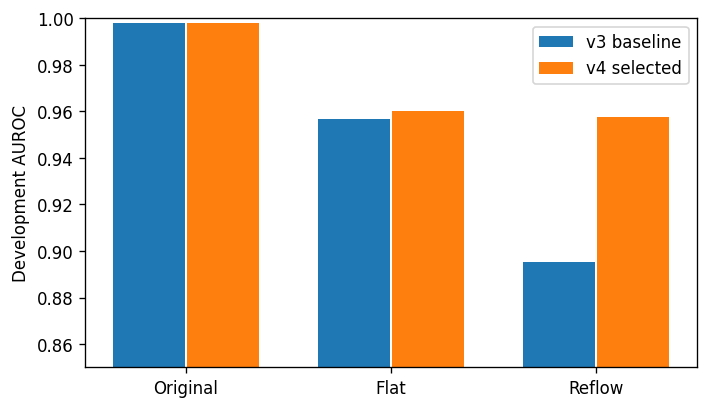

In [6]:
needed=sorted(set(chosen)|{0,1});dev_components={}
for j in needed:
    c=configs[j];zs=get_matrices(c)
    model=fit_model(c,[z[tr] for z in zs],y);anchors=scores(model,zs[0][tr])
    dev_components[j]=np.asarray([ranks(scores(model,z[va]),anchors) for z in zs])
dev_rank=sum(w*dev_components[j] for j,w in chosen.items())
baseline_rank=.75*dev_components[0]+.25*dev_components[1]
dev_probability=calibrator.predict_proba(dev_rank[0].reshape(-1,1))[:,1]
comparison=pd.DataFrame({'view':['Original','Flat','Reflow'],
                         'v3_baseline':[roc_auc_score(yv,p) for p in baseline_rank],
                         'v4_selected':[roc_auc_score(yv,p) for p in dev_rank]})
print(comparison.to_string(index=False))
print('Selected original log loss:',log_loss(yv,dev_probability))
comparison.to_csv(OUT/'development_comparison.csv',index=False)
pd.DataFrame({'id':train.id.to_numpy()[va],'label':yv,'probability':dev_probability}).to_csv(OUT/'validation_predictions.csv',index=False)
summary={'seed':SEED,'components':{j:{'weight':w,'config':configs[j]} for j,w in chosen.items()},'development':comparison.to_dict(orient='records'),'training_selection':blend_table.iloc[0].to_dict()}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
fig,ax=plt.subplots(figsize=(6,3.5));positions=np.arange(3)
ax.bar(positions-.18,comparison.v3_baseline,width=.35,label='v3 baseline')
ax.bar(positions+.18,comparison.v4_selected,width=.35,label='v4 selected')
ax.set_xticks(positions,comparison.view);ax.set_ylim(.85,1);ax.set_ylabel('Development AUROC');ax.legend();fig.tight_layout();plt.show()

## Step 5: Final Full-Data Predictions
Fix the selected configurations and weights. Regenerate three-fold OOF scores on all 10,000 labeled rows for sigmoid calibration, then refit every selected component on all labeled originals and their training-only formatting copies. Transform test text after model selection and align predictions to sample submission IDs.

In [7]:
yfull=train.label.to_numpy();folds_full=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,yfull))
test_views=[test.text.astype(str),test.text.map(canonicalize),test.text.map(reflow)]
test_frames=[pd.DataFrame([rich_features(t) for t in view]) for view in test_views]
test_matrices=[f.to_numpy() for f in test_frames]
full_oof=np.zeros((3,len(train)));test_rank=np.zeros(len(test))
for j,w in chosen.items():
    c=configs[j];zs=get_matrices(c)
    ztest=test_matrices[0][:,base_columns] if c['features']=='base' else test_matrices[0]
    for a,b in folds_full:
        model=fit_model(c,[z[a] for z in zs],yfull[a]);anchors=scores(model,zs[0][a])
        for v in range(3):full_oof[v,b]+=w*ranks(scores(model,zs[v][b]),anchors)
    model=fit_model(c,zs,yfull);anchors=scores(model,zs[0])
    test_rank+=w*ranks(scores(model,ztest),anchors)
    print('Refitted:',j,c,flush=True)
final_calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(full_oof.reshape(-1,1),np.tile(yfull,3))
submission=pd.DataFrame({'id':test.id,'label':final_calibrator.predict_proba(test_rank.reshape(-1,1))[:,1]})
submission=submission.set_index('id').loc[sample.id].reset_index()
assert list(submission)==['id','label'] and len(submission)==3000 and submission.id.is_unique
assert submission.id.tolist()==sample.id.tolist() and set(submission.id)==set(test.id)
assert np.isfinite(submission.label).all() and submission.label.between(0,1).all()
submission.to_csv(OUT/'submission_yx752_v4.csv',index=False)
print('Saved 3,000 test probabilities to v4_results/submission_yx752_v4.csv')

Refitted: 0 {'family': 'hgb', 'features': 'base', 'leaves': 31, 'l2': 1, 'aug': 0.25, 'mode': 'flat'}
Refitted: 6 {'family': 'hgb', 'features': 'rich', 'leaves': 31, 'l2': 1, 'aug': 0.5, 'mode': 'both'}
Saved 3,000 test probabilities to v4_results/submission_yx752_v4.csv


## Results
The selected model combines 25% of the 73-feature v3 boosting component with 75% of a 104-feature boosting model trained with 50% formatting augmentation. Both have 31 leaves and L2 regularization 1. The richer component divides its augmentation equally between flat and reflowed copies. The training OOF AUROCs are 0.994793 original, 0.958671 flat and 0.955441 reflow; its weighted selection score is 0.975925.

On the same development rows, original-text AUROC changes from 0.997979 to 0.997888, flat-format AUROC from 0.956759 to 0.960146, and reflowed-text AUROC from 0.895093 to 0.957513. The ordinary score is essentially unchanged while the tested formatting sensitivity improves. This comparison does not isolate the contribution of each new feature or establish a higher Kaggle score. The selected final model uses two boosting components; SVM candidates were evaluated but not selected.

The shared development set has been inspected across iterations, and the OOF scores are used for model selection. Synthetic formatting variants cover only specific changes. V3 remains the scored baseline with public AUROC 0.97546; v4 public and private scores are unknown. All final predictions use refits on the full supplied labeled dataset.